In [1]:
from openai import OpenAI
import os
import json
import re

In [ ]:
API_KEY = ""
MODEL = "~deepseek/deepseek-flash-latest"
CORPUS_FILE_PATH = "./annotations_remarks/annotated_corpus"
OUTPUT_PATH = "./outputs/"
ANNOTATIONS_PATH = "./annotations_remarks/annotations"

os.makedirs(OUTPUT_PATH, exist_ok=True)

In [4]:
client = OpenAI(base_url="https://openrouter.ai/api/v1",api_key=API_KEY)

## 1. Extracting events

### Prompting LLM

In [116]:
SYSTEM_PROMPT = """
CONTEXT: You are an annotator. Your job is to extract and annotate events in texts. 

ADDITIONAL CONTEXT:
The texts that you work on are in Modern Chinese, Ancient Chinese and English.
You extract only the events that have a temporal marker : a date, an expression (such as "last week", "after the meeting", "in the spring")
You pay attention to non-standard time expressions in classic Chinese (such as 鸡鸣, 东风解冻 or 一炷香).
Time may be given in either ISO format (YYYY-mm-dd) or in dynasty, era, reign, sexagenary, month and/or season, double hour format. 
Dates are not to be converted, slots are filled in the original format expressed in the text. 

MANDATORY RESPONSE FORMAT: A JSON structured text. 
Expected JSON structure:
{"events":
    [
        {"event_id": "prefix+integer",
        "event_name": "string inspired by one or more texts", 
        "event_sources":
        [{"filename": "str",
        "time_related_expr":["str"],
        "position_in_text":["int : first character"]}        
        ],
        "time_start": "tuple(min_start_timestamp, max_start_timestamp) OR Null)",
        "time_end": "tuple(min_end_timestamp, max_end_timestamp) OR Null)",
        "range": "tuple of tuples: (min(unit,value), max(unit,value)) OR Null"
    }
    ]
}

INSTRUCTIONS :
- DO NOT INVENT time if not explicitely given in the text
- **DO NOT INFER** time information to fill all slots
- DO NOT CONVERT into ISO format if date is not given in ISO format.
- CREATE "event_id", a unique identifier for each event, using the filename
- DO NOT CREATE ANY OTHER INFORMATION than event_id
"""

In [ ]:
SYSTEM_PROMPT_EVENT_DEF = """
CONTEXT: You are an annotator. Your job is to extract and annotate events in texts. 

ADDITIONAL CONTEXT:
The texts that you work on are in Modern Chinese, Ancient Chinese and English.
An event is a happenstance mentioned in the text alongside a time marker (date, "last week", "during a meeting", etc.)
We do not count future events expressed with conditionality ("should", "is expected to", etc.)
Time markers can be relative to other events ("after the meeting", "before he accepted the engineering job")
You extract only the events that have a temporal marker : a date or an expression (such as "last week", "after the meeting", "in the spring")
You pay attention to non-standard time expressions in classic Chinese (such as 鸡鸣, 东风解冻 or 一炷香).
Time may be given in either ISO format (YYYY-mm-dd) or in dynasty, era, reign, sexagenary, month and/or season, double hour format. 
Dates are not to be converted, slots are filled in the original format expressed in the text. 

MANDATORY RESPONSE FORMAT: A JSON structured text. 
Expected JSON structure:
{"events":
    [
        {"event_id": "prefix+integer",
        "event_name": "string inspired by one or more texts", 
        "event_sources":
        [{"filename": "str",
        "time_related_expr":["str"],
        "position_in_text":["int : first character"]}        
        ],
        "time_start": "tuple(min_start_timestamp, max_start_timestamp) OR Null)",
        "time_end": "tuple(min_end_timestamp, max_end_timestamp) OR Null)",
        "range": "tuple of tuples: (min(unit,value), max(unit,value)) OR Null"
    }
    ]
}

INSTRUCTIONS :
- DO NOT INVENT time if not explicitely given in the text
- **DO NOT INFER** time information to fill all slots
- DO NOT CONVERT into ISO format if date is not given in gregorian calendar.
- CREATE "event_id", a unique identifier for each event, using the filename
- DO NOT CREATE ANY OTHER INFORMATION than event_id
"""

In [118]:
corpus = []
for filename in os.listdir(CORPUS_FILE_PATH):
    filepath = os.path.join(CORPUS_FILE_PATH, filename)
    if os.path.isfile(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            corpus.append((filename, f.read()))
if not corpus:
    raise ValueError("Aucun fichier trouvé dans CORPUS_FILE_PATH — vérifiez le chemin.")

corpus_text = "\n\n".join(
    f"### FILE: {filename}\n{content}" for filename, content in corpus
)

In [122]:
def send_data_llm(event_def:bool=False):
    if event_def:
        messages = [
    {"role": "system", "content": SYSTEM_PROMPT_EVENT_DEF},
    {"role": "user","content": corpus_text}
        ]
    else :
        messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user","content": corpus_text}
        ]
    try:
        response = client.chat.completions.create(
            model=MODEL,
            messages=messages, #[{'role':'user', 'content':"say hi"}],
            temperature=0.3,
            extra_body={"reasoning": {"effort": "none"}}
        )
    except Exception as e:
        print(f"Erreur lors de l'appel à l'API : {e}")
    
    raw = response.choices[0].message.content
    try :
        cleaned = re.sub(r"^```json|```$", "", raw.strip(), flags=re.MULTILINE).strip()
        data = json.loads(cleaned)
        return data
    except:
        print("error !")
        return raw

In [123]:
data_def  = send_data_llm(event_def=True)

In [126]:
output_file = os.path.join(OUTPUT_PATH, "extraction_events_final_schema_event_def.json")
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(data_def, f, ensure_ascii=False, indent=2)

In [127]:
data_no_def = send_data_llm(event_def=False)

In [128]:
output_file = os.path.join(OUTPUT_PATH, "extraction_events_final_schema.json")
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(data_no_def, f, ensure_ascii=False, indent=2)

### "Evaluation" of extractions

In [129]:
from collections import Counter 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [130]:
annotations = []
for filename in os.listdir(ANNOTATIONS_PATH):
    filepath = os.path.join(ANNOTATIONS_PATH, filename)
    if os.path.isfile(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            print(filepath)
            annotation_raw =f.read()
            annot = json.loads(annotation_raw)
            annot = annot[list(annot.keys())[0]]
            annotations.append(annot)

./annotations_remarks/annotations/po_en_1669.json
./annotations_remarks/annotations/annotations_enc_rotary_en_1319854677.json
./annotations_remarks/annotations/INSCR-KR4d0232-WYG-f006-0002.json
./annotations_remarks/annotations/annotations_enc_rotary_cmn_SPSP193109022001.json
./annotations_remarks/annotations/structure_example_TW_po_zh_8342_ZC.json
./annotations_remarks/annotations/structure_example_TW_po_zh_2376.json
./annotations_remarks/annotations/annotations_enc_rotary_en_1319843498.json
./annotations_remarks/annotations/annotations_enc_exp_cmn_SPSP192606271118.json
./annotations_remarks/annotations/annotations_enc_exp_cmn_SPSP192708311019.json
./annotations_remarks/annotations/po_en_1.json
./annotations_remarks/annotations/annotations_enc_rotary_cmn_SPSP192506121501.json
./annotations_remarks/annotations/INSCR-KR4d0466-WYG-f011-0010.json


#### Counting events extracted and comparing

In [131]:
counter_annot_per_corpus = Counter()
for annot in annotations :
    name_corpus = annot["sources"][0][0]
    name_corpus = name_corpus.split("/")[-1].split(".")[0]
    counter_annot_per_corpus[name_corpus]=len(annot["events"])

In [132]:
def count_extractions(data):
    corpus_events_extracted = []
    for i in range(len(data["events"])):
        event_id = data["events"][i]["event_id"]
        corpus_events_extracted.append("_".join(event_id.split("_")[:-1]))
    return Counter(corpus_events_extracted)

In [133]:
counter_events_per_corpus_def = count_extractions(data_def)

In [134]:
counter_events_per_corpus_no_def = count_extractions(data_no_def)
counter_events_per_corpus_no_def

Counter({'1319843498': 13,
         '1319854677': 11,
         'SPSP192708311019': 5,
         'KR4d0466-WYG-f011-0010': 4,
         'KR4d0232-WYG-f006-0002': 4,
         'po_zh_8342': 3,
         'po_zh_2376': 2,
         'SPSP192606271118': 2,
         'po_en_1669': 1,
         'SPSP192506121501': 1,
         'po_en_1': 1,
         'SPSP193109022001': 1})

In [135]:
df = pd.concat(
    [pd.Series(counter_annot_per_corpus, name='annotated'), 
     pd.Series(counter_events_per_corpus_def, name='extracted_def'),
     pd.Series(counter_events_per_corpus_no_def, name='extracted_no_def')],
    axis=1
)

In [136]:
df

,annotated,extracted_def,extracted_no_def
po_en_1669,1,1,1
1319854677,18,11,11
KR4d0232-WYG-f006-0002,4,4,4
SPSP193109022001,2,1,1
po_zh_8342,7,3,3
po_zh_2376,2,2,2
1319843498,15,10,13
SPSP192606271118,6,2,2
SPSP192708311019,10,5,5
po_en_1,3,1,1


In [137]:
def metrics(matrix_conf, col_annot, col_extract):
    matrix_conf["matched"] = matrix_conf[[col_extract, col_annot]].min(axis=1)
    matrix_conf["over_extracted"] = matrix_conf[col_extract] - matrix_conf["matched"]
    matrix_conf["under_extracted"] = matrix_conf[col_annot] - matrix_conf["matched"]
    
    matched = matrix_conf["matched"].sum()
    total_extracted = matrix_conf[col_extract].sum()
    total_annotated = matrix_conf[col_annot].sum()
    
    precision = matched / total_extracted if total_extracted else float("nan")
    recall = matched / total_annotated if total_annotated else float("nan")
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else float("nan")
    
    print(f"total extracted = {total_extracted}, total annotated = {total_annotated}, matched (capped) = {matched}")
    print(f"Precision = {precision:.3f}")
    print(f"Recall    = {recall:.3f}")
    print(f"F1        = {f1:.3f}")


In [138]:
print("With event definition")
metrics(df, col_annot="annotated", col_extract="extracted_def")

print("Without event definition")
metrics(df, col_annot="annotated", col_extract="extracted_no_def")

With event definition
total extracted = 45, total annotated = 75, matched (capped) = 45
Precision = 1.000
Recall    = 0.600
F1        = 0.750
Without event definition
total extracted = 48, total annotated = 75, matched (capped) = 48
Precision = 1.000
Recall    = 0.640
F1        = 0.780


Text(0.5, 1.0, 'Event \ndef')

<Figure size 600x600 with 0 Axes>

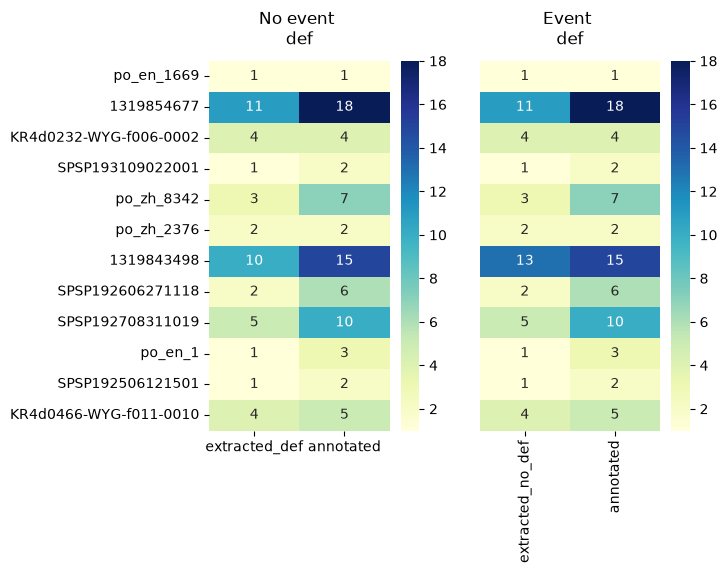

In [139]:
# --- heatmap: extracted vs annotated counts, per file ---
plt.figure(figsize=(6, 6))
fig, (ax,ax2) = plt.subplots(ncols=2)

pivot1 = df[["extracted_def", "annotated"]]
pivot2 = df[["extracted_no_def", "annotated"]]
sns.heatmap(pivot1, annot=True, fmt="d", cmap="YlGnBu", cbar=True, ax=ax)
sns.heatmap(pivot2, annot=True, fmt="d", cmap="YlGnBu", cbar=True, ax=ax2, yticklabels=False)
ax.set_title("No event \ndef", pad=12)
ax2.set_title("Event \ndef", pad=12)


## Extraction of relations

Important :
In order to avoid multiplying error, we provide the LLM with "gold standard" (i.e. hand-annotated) events. This ensures that if the relations are not properly extracted, it is not because the events are wrong, but really because the LLM struggled extracting the relations

Also, this allows us to check that the relations are really between correct entities, because we know the ids of the "true" relations

### Prompting LLM

In [140]:
SYSTEM_PROMPT_REL = """
CONTEXT: You are an annotator. Your job is to extract the relation between events in texts.

ADDITIONAL CONTEXT:
The texts that you work on are in Modern Chinese, Ancient Chinese and English.
Time may be given in either ISO format (YYYY-mm-dd) or in dynasty, era, reign, sexagenary, month and/or season, double hour format. 
You receive the events structured under the following format :
{
    "events":
    [
        {"event_id": "prefix+integer",
        "event_name": "string inspired by one or more texts", 
        "event_sources":
        [{"filename": "str",
        "time_related_expr":["str"],
        "position_in_text":["int : first character"]}        
        ],
        "time_start": "tuple(min_start_timestamp, max_start_timestamp) OR Null)",
        "time_end": "tuple(min_end_timestamp, max_end_timestamp) OR Null)",
        "range": "tuple of tuples: (min(unit,value), max(unit,value)) OR Null"
    }
    ]
}

MANDATORY RESPONSE FORMAT: A JSON structured text. 
Expected JSON structure:
{"event_relations":
    [
        {"relation_id": "event_idA_event_idB",
        "event_idA":"",
        "event_idB":"",
        "relation_type": "choose between <before, equals, overlaps, during, starts, finishes, meets>",
        "span_between": "(min(unit,value), max(unit,value)), 0, Null",
        "relation_sources":
            [{"filename": "str",
            "time_related_expr":["str"],
            "position_in_text":["int : first character"]}        
            ]
    }
    ]
}

INSTRUCTIONS :
- DO NOT INVENT time if not explicitely given in the text
- **DO NOT INFER** time information
- DO NOT CONVERT into ISO format if date is not given in ISO format.
"""

In [172]:
annotations_events = []
annotations_rel = []
for filename in os.listdir(ANNOTATIONS_PATH):
    filepath = os.path.join(ANNOTATIONS_PATH, filename)
    if os.path.isfile(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            print(filepath)
            annotation_raw =f.read()
            annot = json.loads(annotation_raw)
            annot = annot[list(annot.keys())[0]]
            annotations_events.append(annot["events"])
            annotations_rel.extend(annot["event_relations"])

./annotations_remarks/annotations/po_en_1669.json
./annotations_remarks/annotations/annotations_enc_rotary_en_1319854677.json
./annotations_remarks/annotations/INSCR-KR4d0232-WYG-f006-0002.json
./annotations_remarks/annotations/annotations_enc_rotary_cmn_SPSP193109022001.json
./annotations_remarks/annotations/structure_example_TW_po_zh_8342_ZC.json
./annotations_remarks/annotations/structure_example_TW_po_zh_2376.json
./annotations_remarks/annotations/annotations_enc_rotary_en_1319843498.json
./annotations_remarks/annotations/annotations_enc_exp_cmn_SPSP192606271118.json
./annotations_remarks/annotations/annotations_enc_exp_cmn_SPSP192708311019.json
./annotations_remarks/annotations/po_en_1.json
./annotations_remarks/annotations/annotations_enc_rotary_cmn_SPSP192506121501.json
./annotations_remarks/annotations/INSCR-KR4d0466-WYG-f011-0010.json


In [153]:
corpus = []
for filename in os.listdir(CORPUS_FILE_PATH):
    filepath = os.path.join(CORPUS_FILE_PATH, filename)
    if os.path.isfile(filepath):
        with open(filepath, "r", encoding="utf-8") as f:
            corpus.append((filename, f.read()))
if not corpus:
    raise ValueError("Aucun fichier trouvé dans CORPUS_FILE_PATH — vérifiez le chemin.")

corpus_text = "\n\n".join(
    f"### FILE: {filename} \n ### CONTENT {content}" for filename, content in corpus
)
annotations_text = f"### EVENTS {json.dumps(annotations_events)}"

In [161]:
def ask_llm_relations():
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT_REL},
        {"role": "user","content": corpus_text},
        {"role": "user","content": annotations_text}
    ]
    try:
        response = client.chat.completions.create(
            model=MODEL,
            messages=messages, #[{'role':'user', 'content':"say hi"}],
            temperature=0.3,
            extra_body={"reasoning": {"effort": "none"}}
        )
        #print(response.choices[0].message.content)
    except Exception as e:
        print(f"Erreur lors de l'appel à l'API : {e}")

    raw = response.choices[0].message.content
    cleaned = re.sub(r"^```json|```$", "", raw.strip(), flags=re.MULTILINE).strip()
    data = json.loads(cleaned)
    return data

In [162]:
rel_extractions = ask_llm_relations()

In [163]:
output_file = os.path.join(OUTPUT_PATH, "extracted_relations.json")
with open(output_file, "w", encoding="utf-8") as f:
    json.dump(rel_extractions, f, ensure_ascii=False, indent=2)

In [210]:
true_rel = [(rel["event_idA"],rel["event_idB"], rel["relation_type"]) for rel in annotations_rel if len(rel["event_idA"])>0]
predicted_rel = [(rel["event_idA"],rel["event_idB"], rel["relation_type"]) for rel in rel_extractions["event_relations"]]

In [211]:
#build dfs of pairs + relation type
def to_df(pairs, type_col):
    recs = [{'idA': p[0], 'idB': p[1], type_col: (p[2] if len(p) > 2 else None)}
            for p in pairs]
    return pd.DataFrame(recs, columns=['idA', 'idB', type_col])

gold_df = to_df(true_rel, 'type_gold').dropna(subset=["idA", "idB"])
pred_df = to_df(predicted_rel, 'type_pred').dropna(subset=["idA", "idB"])

gold_set = set(zip(gold_df.idA, gold_df.idB))
pred_set = set(zip(pred_df.idA, pred_df.idB))

In [212]:
#merge dfs, so that not all pairs get input in the matrix but only those that got either predicted or were true
#sparse approahc

merged = gold_df.merge(pred_df, on=['idA', 'idB'], how='outer', indicator=True)

def classify(row):
    a, b = row['idA'], row['idB']
    if row['_merge'] == 'both': #if a relation was predicted in both left (gold) and right (pred) df
        if pd.isna(row['type_gold']) or row['type_gold'] == row['type_pred']: # if relation type is correctly predicted
            return 'correct'
        return 'wrong_type' 
    if row['_merge'] == 'left_only': #if only was predicted in the left (gold) df
        return 'reversed' if (b, a) in pred_set else 'missing'
    return 'reversed' if (b, a) in gold_set else 'extra' #all the extra cases: it is not in gold but predicted

merged['status'] = merged.apply(classify, axis=1)
merged = merged.drop(columns='_merge')

In [214]:
def collapse_reversed(df): #cases where A and B are reversed in the relation (A is before B in gold but B before A in pred)
    rev = df[df.status == 'reversed']
    g_side = rev[rev.type_pred.isna()]   # came from gold (left_only)
    p_side = rev[rev.type_gold.isna()]   # came from pred (right_only)
    combined, used = [], set()
    for i, g in g_side.iterrows():
        m = p_side[(p_side.idA == g.idB) & (p_side.idB == g.idA)]
        if not m.empty:
            j = m.index[0]
            combined.append({'idA': g.idA, 'idB': g.idB,
                              'type_gold': g.type_gold, 'type_pred': m.loc[j, 'type_pred'],
                              'status': 'reversed'})
            used |= {i, j}
    return pd.concat([df.drop(index=used), pd.DataFrame(combined)], ignore_index=True)

result = collapse_reversed(merged)

In [215]:
result

,idA,idB,type_gold,type_pred,status
0,1319843498_01,1319843498_02,NaN,before,extra
1,1319843498_01,1319843498_03,NaN,before,extra
2,1319843498_01,1319843498_04,NaN,before,extra
3,1319843498_01,1319843498_05,NaN,before,extra
4,1319843498_01,1319843498_06,NaN,before,extra
...,...,...,...,...,...
138,1319843498_07,1319843498_06,before,before,reversed
139,1319843498_12,1319843498_11,during,during,reversed
140,SPSP193109022001_02,SPSP193109022001_01,during,during,reversed
141,TW_002,TW_001,during,equals,reversed


In [216]:
colors = {'correct': '#d4f4dd', 'wrong_type': '#fff3cd', 'reversed': '#ffe0b2',
          'missing': '#f8d7da', 'extra': '#d1ecf1'}
result.sort_values('status').style.map(
    lambda v: f'background-color: {colors.get(v, "")}', subset=['status']
)

,idA,idB,type_gold,type_pred,status
115,SPSP192606271118_05,SPSP192606271118_06,before,before,correct
111,SPSP192606271118_01,SPSP192606271118_02,before,before,correct
114,SPSP192606271118_04,SPSP192606271118_05,before,before,correct
117,SPSP192708311019_02,SPSP192708311019_03,before,before,correct
118,SPSP192708311019_03,SPSP192708311019_04,before,before,correct
119,SPSP192708311019_04,SPSP192708311019_05,before,before,correct
54,1319843498_09,1319843498_10,before,before,correct
121,SPSP192708311019_06,SPSP192708311019_07,before,before,correct
123,SPSP192708311019_08,SPSP192708311019_09,before,before,correct
110,SPSP192506121501_01,SPSP192506121501_02,before,before,correct


In [217]:
counts = result['status'].value_counts().reindex(
    ['correct', 'wrong_type', 'reversed', 'missing', 'extra']).fillna(0).astype(int)

correct = counts['correct']
precision = correct / len(pred_df) if len(pred_df) else float('nan')
recall = correct / len(gold_df) if len(gold_df) else float('nan')
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else float('nan')

print(f"Precision: {precision:.1%}   Recall: {recall:.1%}   F1: {f1:.1%}")
counts.to_frame('count')

Precision: 11.8%   Recall: 57.1%   F1: 19.5%


,count
status,
correct,16
wrong_type,0
reversed,5
missing,7
extra,115


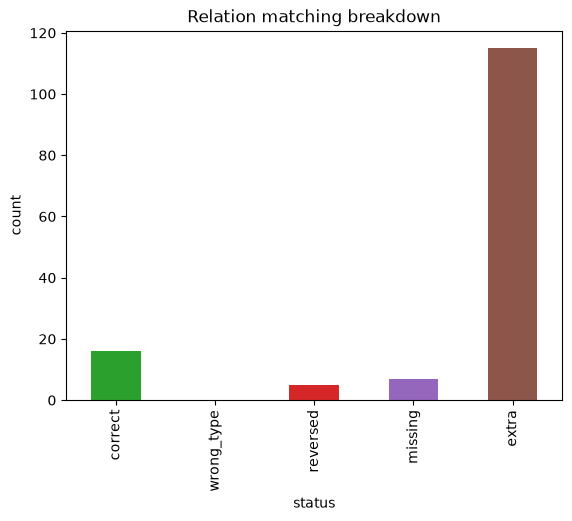

In [218]:
import matplotlib.pyplot as plt
counts.plot(kind='bar', color=['#2ca02c', '#ff7f0e', '#d62728', '#9467bd', '#8c564b'])
plt.title('Relation matching breakdown')
plt.ylabel('count')
plt.show()